## 📌 1. Configuração Inicial

In [1]:
#modelo = "llama3:70b"
modelo ="qwen2.5-coder:32b"
platform = "npm"
extension = "v2"
#extension = "v1"

import pandas as pd
from pathlib import Path
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Caminho para o arquivo de resultados
file_path = Path(f"../data/output/{modelo}/{platform}/{extension}.json")
#file_path = Path(f"../data/output/{modelo}/{platform}/feat_formatted_{extension}.json")

with open(file_path, "r") as f:
    data = json.load(f)

df = pd.DataFrame(data["results"])
df.head()


,input_text,type,reason,raw_response,label,correct,breaking_change,expected_breaking_change,breaking_correct,processing_time,commit_hash,timestamp
0,Commit Message:\nexit developer preview for bu...,refactor,The commit removes warnings related to the dev...,Type: refactor \nBreaking_Change: False \nRe...,refactor,True,False,False,True,0.973991,7cb04d1d,2025-07-25T03:08:26.852681
1,Commit Message:\ncut the v19.0.0-next.1 releas...,chore,The commit includes a breaking change related ...,Type: chore \nBreaking_Change: True \nReason...,others,False,True,False,False,2.540453,9e87593055a5314a67090bd15d5552c23b538050,2025-07-25T03:08:28.410818
2,Commit Message:\nfix `peformance.now()` not av...,fix,The commit fixes an issue where `performance.n...,Type: fix \nBreaking_Change: False \nReason:...,refactor,False,False,False,True,3.304989,78ffc52f,2025-07-25T03:08:29.176010
3,Commit Message:\nReturn NOT_FOUND for retrieve...,fix,The change modifies the behavior of the `retri...,Type: fix \nBreaking_Change: True \nReason: ...,refactor,False,True,False,False,4.660252,26dfe6df,2025-07-25T03:08:30.533690
4,Commit Message:\nre-enable adev tests (#58574)...,test,The commit re-enables tests that were previous...,Type: test \nBreaking_Change: False \nReason...,ci,False,False,False,True,5.667587,f5de7a5bba1a4dfcbb83cc6afd50753c9966020e,2025-07-25T03:08:31.538043


### 📌 2. Gerar relatório detalhado


In [2]:
classes = ['feat', 'fix', 'docs', 'style', 'refactor', 'perf',
           'test', 'build', 'ci', 'chore', 'others']

report = classification_report(
    df['label'],
    df['type'],
    labels=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose().loc[classes]
report_df["support"] = report_df["support"].astype(int)
report_df.reset_index(inplace=True)
report_df.rename(columns={"index": "class"}, inplace=True)

total = report_df["support"].sum()
total_row = {
    "class": "Total",
    "precision": float("nan"),
    "recall": float("nan"),
    "f1-score": float("nan"),
    "support": total
}

total_df = pd.DataFrame([total_row], columns=report_df.columns)


report_df = pd.concat([report_df, total_df], ignore_index=True)


def format_metric(value):
    if pd.isna(value):
        return "-"
    return f"{value:.2f}"

for col in ["precision", "recall", "f1-score"]:
    report_df[col] = report_df[col].apply(format_metric)

report_df


,class,precision,recall,f1-score,support
0,feat,0.24,0.82,0.37,17
1,fix,0.42,0.65,0.51,55
2,docs,0.98,0.51,0.68,101
3,style,0.00,0.00,0.00,0
4,refactor,0.62,0.51,0.56,119
5,perf,0.14,1.00,0.25,1
6,test,0.71,0.56,0.62,9
7,build,0.71,0.62,0.66,55
8,ci,0.00,0.00,0.00,12
9,chore,0.00,0.00,0.00,0


### Total por classe

In [3]:
df["acerto"] = df["label"] == df["type"]

support_per_class = df["label"].value_counts().rename("total")

acertos_per_class = df[df["acerto"]]["label"].value_counts().rename("acertos")

resultado = pd.concat([support_per_class, acertos_per_class], axis=1).fillna(0)
resultado["erros"] = resultado["total"] - resultado["acertos"]

resultado = resultado.astype({ "acertos": int, "erros": int, "total": int})

resultado = resultado[["acertos", "erros", "total"]]

resultado = resultado.sort_values(by="total", ascending=False)

resultado

,acertos,erros,total
label,,,
refactor,61,58,119
docs,52,49,101
build,34,21,55
fix,36,19,55
feat,14,3,17
others,1,14,15
ci,0,12,12
test,5,4,9
perf,1,0,1


### Confusao

In [4]:
from sklearn.metrics import multilabel_confusion_matrix

labels = sorted(df["label"].unique())
mcm = multilabel_confusion_matrix(df["label"], df["type"], labels=labels)

confusion_data = []
for label, matrix in zip(labels, mcm):
    tn, fp, fn, tp = matrix.ravel()
    confusion_data.append({
        "classe": label,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

confusion_df = pd.DataFrame(confusion_data).set_index("classe")
confusion_df = confusion_df.sort_values(by="TP", ascending=False)
confusion_df


,TP,FP,FN,TN
classe,,,,
refactor,61,38,58,227
docs,52,1,49,282
fix,36,50,19,279
build,34,14,21,315
feat,14,44,3,323
test,5,2,4,373
perf,1,6,0,377
others,1,1,14,368
ci,0,3,12,369


### 📌 Relatório de Classificação


In [5]:
from sklearn.metrics import classification_report, accuracy_score

labels = [
    'feat', 'fix', 'docs', 'style', 'refactor', 'perf',
    'test', 'build', 'ci', 'chore', 'others',
]

print(classification_report(df['label'], df['type'], labels=labels, zero_division=0))

# Acurácia geral
accuracy = accuracy_score(df['label'], df['type'])
print(f"Accuracy: {accuracy:.2%}")


              precision    recall  f1-score   support

        feat       0.24      0.82      0.37        17
         fix       0.42      0.65      0.51        55
        docs       0.98      0.51      0.68       101
       style       0.00      0.00      0.00         0
    refactor       0.62      0.51      0.56       119
        perf       0.14      1.00      0.25         1
        test       0.71      0.56      0.62         9
       build       0.71      0.62      0.66        55
          ci       0.00      0.00      0.00        12
       chore       0.00      0.00      0.00         0
      others       0.50      0.07      0.12        15

    accuracy                           0.53       384
   macro avg       0.39      0.43      0.34       384
weighted avg       0.66      0.53      0.56       384

Accuracy: 53.12%


### Matriz de Confusão


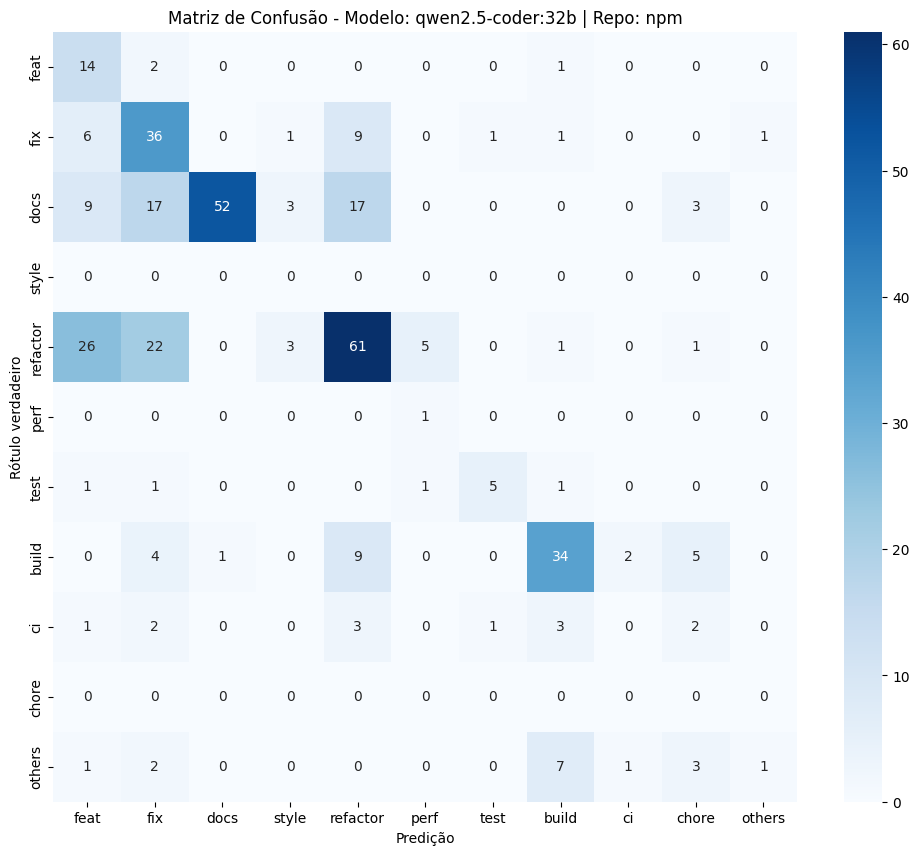

In [6]:
cm = confusion_matrix(df['label'], df['type'], labels=[
    'feat', 'fix', 'docs', 'style', 'refactor', 'perf',
    'test', 'build', 'ci', 'chore', 'others'
])

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predição")
plt.ylabel("Rótulo verdadeiro")
plt.title(f"Matriz de Confusão - Modelo: {modelo} | Repo: {platform}")
plt.show()


### Tamanho do texto vs. acertos/erros

Estatísticas descritivas por classe (input_length):
            count         mean          std    min     25%     50%     75%  \
is_correct                                                                   
Acerto      162.0  2320.580247  2309.799880  176.0  725.25  1468.5  2863.5   
Erro        143.0  2057.027972  2174.382117  176.0  470.50  1205.0  2716.5   

               max  
is_correct          
Acerto      9927.0  
Erro        9577.0  


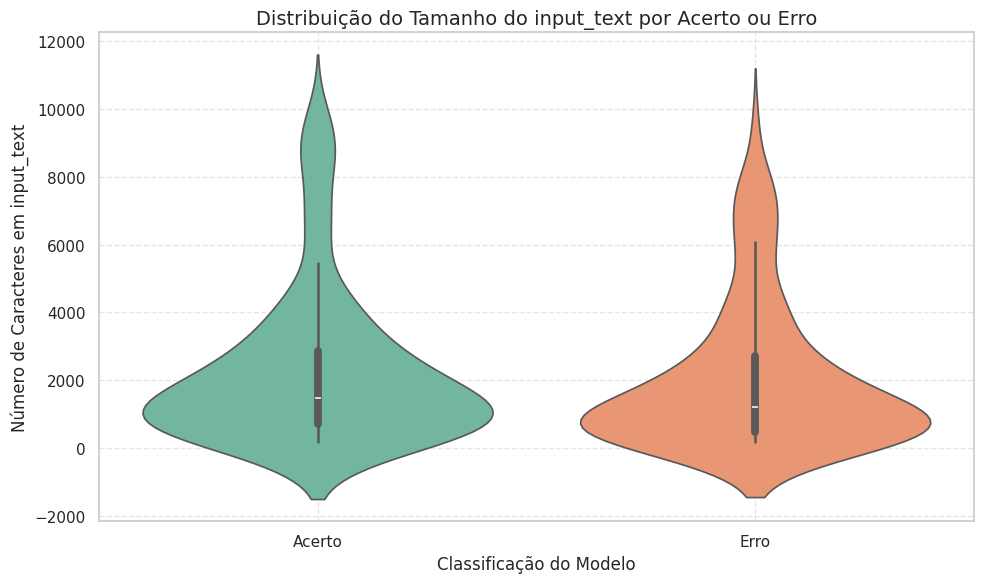

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df['input_length'] = df['input_text'].apply(len)
df['is_correct'] = df['correct'].map({True: 'Acerto', False: 'Erro'})

limite_superior = 10000
df_filtered = df[df['input_length'] <= limite_superior]

print("Estatísticas descritivas por classe (input_length):")
print(df_filtered.groupby('is_correct')['input_length'].describe())

sns.set(style="whitegrid")
plt.figure(figsize=(10, 6))

sns.violinplot(data=df_filtered, x="is_correct", y="input_length", hue="is_correct", palette="Set2", legend=False)

plt.title("Distribuição do Tamanho do input_text por Acerto ou Erro", fontsize=14)
plt.xlabel("Classificação do Modelo", fontsize=12)
plt.ylabel("Número de Caracteres em input_text", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Quebras de Compatibilidade

In [41]:
df_breaking = df[df['breaking_change'] == True]

total = len(df_breaking)
correct = df_breaking['breaking_correct'].sum()
incorrect = total - correct

taxa_acerto = (correct / total) * 100 if total > 0 else 0
taxa_erro = (incorrect / total) * 100 if total > 0 else 0

break_summary = pd.DataFrame([{
    "Total Breaking Changes": total,
    "Acertos": correct,
    "Erros": incorrect,
    "Taxa de Acerto (%)": f"{taxa_acerto:.2f}%",
    "Taxa de Erro (%)": f"{taxa_erro:.2f}%"
}])

display(break_summary)


,Total Breaking Changes,Acertos,Erros,Taxa de Acerto (%),Taxa de Erro (%)
0,76,13,63,17.11%,82.89%


### Quebras de Compatibilidade 2

In [42]:
is_breaking = df['breaking_change'] == True
predicted_breaking = df['type'] == 'breaking' 

# TP: É breaking e modelo acertou
TP = ((is_breaking) & (df['breaking_correct'] == True)).sum()

# FN: É breaking, mas modelo errou
FN = ((is_breaking) & (df['breaking_correct'] == False)).sum()

# FP: Não é breaking, mas modelo previu breaking
FP = ((~is_breaking) & (predicted_breaking)).sum()

# TN: Não é breaking e modelo também não previu breaking
TN = ((~is_breaking) & (~predicted_breaking)).sum()

breaking_matrix = pd.DataFrame([{
    "True Positive (TP)": TP,
    "False Positive (FP)": FP,
    "False Negative (FN)": FN,
    "True Negative (TN)": TN
}])

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print(f"Precisão: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}")


display(breaking_matrix)

Precisão: 1.00
Recall: 0.17
F1-Score: 0.29


,True Positive (TP),False Positive (FP),False Negative (FN),True Negative (TN)
0,13,0,63,143


### Comparando execuções

In [3]:
from pathlib import Path
import pandas as pd
import json
from sklearn.metrics import classification_report, accuracy_score

modelo = "qwen2.5-coder:32b"
repositorio = "npm"
versoes = ["E2_v5", "E2_v6"]  
classes = ['feat', 'fix', 'docs', 'style', 'refactor', 'perf', 'test', 'build', 'ci', 'chore', 'others']

reports = {}
accuracies = {}

for versao in versoes:
    path = Path(f"../data/output/{modelo}/{repositorio}/{versao}.json")
    with open(path) as f:
        data = json.load(f)

    df = pd.DataFrame(data["results"])
    report = classification_report(df['label'], df['type'], labels=classes, output_dict=True, zero_division=0)
    df_report = pd.DataFrame(report).transpose().loc[classes]
    df_report["support"] = df_report["support"].astype(int)
    reports[versao] = df_report
    accuracies[versao] = accuracy_score(df['label'], df['type'])

renamed_reports = {}
for versao in versoes:
    renamed = reports[versao].copy()
    renamed.columns = [f"{col}_{versao}" for col in renamed.columns]
    renamed_reports[versao] = renamed

comparacao = renamed_reports[versoes[0]].join(renamed_reports[versoes[1]])

comparacao["precision_diff"] = comparacao[f"precision_{versoes[1]}"] - comparacao[f"precision_{versoes[0]}"]
comparacao["recall_diff"] = comparacao[f"recall_{versoes[1]}"] - comparacao[f"recall_{versoes[0]}"]
comparacao["f1-score_diff"] = comparacao[f"f1-score_{versoes[1]}"] - comparacao[f"f1-score_{versoes[0]}"]

comparacao = comparacao[[
    f"precision_{versoes[0]}", f"precision_{versoes[1]}", "precision_diff",
    f"recall_{versoes[0]}", f"recall_{versoes[1]}", "recall_diff",
    f"f1-score_{versoes[0]}", f"f1-score_{versoes[1]}", "f1-score_diff",
    f"support_{versoes[0]}", f"support_{versoes[1]}"
]]

comparacao = comparacao.round(3)

acc_row = pd.DataFrame([{
    f"precision_{versoes[0]}": "-",
    f"precision_{versoes[1]}": "-",
    "precision_diff": "-",
    f"recall_{versoes[0]}": "-",
    f"recall_{versoes[1]}": "-",
    "recall_diff": "-",
    f"f1-score_{versoes[0]}": "-",
    f"f1-score_{versoes[1]}": "-",
    "f1-score_diff": "-",
    f"support_{versoes[0]}": "-",
    f"support_{versoes[1]}": "-"
}], index=["Accuracy"])

comparacao = pd.concat([comparacao, acc_row])

comparacao.loc["Accuracy", f"precision_{versoes[0]}"] = f"{accuracies[versoes[0]]:.3f}"
comparacao.loc["Accuracy", f"precision_{versoes[1]}"] = f"{accuracies[versoes[1]]:.3f}"
comparacao.loc["Accuracy", "precision_diff"] = f"{accuracies[versoes[1]] - accuracies[versoes[0]]:.3f}"

def highlight_diff(val):
    if isinstance(val, (int, float)):
        if val > 0:
            return "color: green"
        elif val < 0:
            return "color: red"
    return ""

styled_comparacao = comparacao.style.map(
    highlight_diff,
    subset=["precision_diff", "recall_diff", "f1-score_diff"]
)

display(styled_comparacao) 

print(f"Acurácia {versoes[0]}: {accuracies[versoes[0]]:.2%}")
print(f"Acurácia {versoes[1]}: {accuracies[versoes[1]]:.2%}")
print(f"Variação de acurácia: {accuracies[versoes[1]] - accuracies[versoes[0]]:+.2%}")


,precision_E2_v5,precision_E2_v6,precision_diff,recall_E2_v5,recall_E2_v6,recall_diff,f1-score_E2_v5,f1-score_E2_v6,f1-score_diff,support_E2_v5,support_E2_v6
feat,0.222000,0.267000,0.044000,0.625000,0.500000,-0.125000,0.328000,0.348000,0.020000,16,16
fix,0.483000,0.361000,-0.122000,0.843000,0.255000,-0.588000,0.614000,0.299000,-0.315000,51,51
docs,0.976000,1.000000,0.024000,0.441000,0.086000,-0.355000,0.607000,0.158000,-0.449000,93,93
style,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0,0
refactor,0.638000,0.462000,-0.177000,0.541000,0.811000,0.270000,0.585000,0.588000,0.003000,111,111
perf,0.100000,0.000000,-0.100000,1.000000,0.000000,-1.000000,0.182000,0.000000,-0.182000,1,1
test,0.556000,0.500000,-0.056000,0.625000,0.625000,0.000000,0.588000,0.556000,-0.033000,8,8
build,0.846000,0.872000,0.026000,0.660000,0.680000,0.020000,0.742000,0.764000,0.022000,50,50
ci,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,12,12
chore,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0,0


Acurácia E2_v5: 55.34%
Acurácia E2_v6: 44.66%
Variação de acurácia: -10.67%


### Comparando os modelos

In [10]:
from pathlib import Path
import pandas as pd
import json
from sklearn.metrics import classification_report, accuracy_score
from IPython.display import display

# 📌 Parâmetros
repositorio = "npm"
versao = "v2"
modelos = ["gemma3", "mistral", "phi4"]
classes = ['feat', 'fix', 'docs', 'refactor', 'perf',
           'test', 'build', 'ci','others']

# 📊 Coletar relatórios
reports = {}
accuracies = {}

for modelo in modelos:
    path = Path(f"data/output/{modelo}/{repositorio}/{versao}.json")
    with open(path) as f:
        data = json.load(f)

    df = pd.DataFrame(data["results"])
    report = classification_report(df['label'], df['type'], labels=classes, output_dict=True, zero_division=0)
    df_report = pd.DataFrame(report).transpose().loc[classes]
    df_report["support"] = df_report["support"].astype(int)
    reports[modelo] = df_report
    accuracies[modelo] = accuracy_score(df['label'], df['type'])

# Renomear colunas com nome do modelo
renamed_reports = {}
for modelo in modelos:
    renamed = reports[modelo].copy()
    renamed.columns = [f"{metric}_{modelo}" for metric in renamed.columns]
    renamed_reports[modelo] = renamed

# Juntar as tabelas
comparacao = pd.concat(renamed_reports.values(), axis=1)

# Reordenar colunas: agrupar por tipo de métrica
metricas = ["precision", "recall", "f1-score", "support"]
colunas_ordenadas = []
for metrica in metricas:
    for modelo in modelos:
        colunas_ordenadas.append(f"{metrica}_{modelo}")

comparacao = comparacao[colunas_ordenadas]

# Linha de acurácia geral
acc_row = {col: "-" for col in comparacao.columns}
for modelo in modelos:
    acc_row[f"precision_{modelo}"] = f"{accuracies[modelo]:.3f}"
comparacao.loc["Accuracy"] = acc_row
comparacao = comparacao.round(3)

# Estilização com negrito e vermelho
def highlight_best_worst(row):
    styles = [""] * len(row)
    for metrica in ["precision", "recall", "f1-score"]:
        valores = []
        col_indices = []
        for i, col in enumerate(row.index):
            if col.startswith(metrica):
                try:
                    val = float(row[col])
                    valores.append((val, i))
                except:
                    pass
        if valores:
            max_val = max(valores, key=lambda x: x[0])[0]
            min_val = min(valores, key=lambda x: x[0])[0]
            for val, idx in valores:
                if val == max_val:
                    styles[idx] = "font-weight: bold; color: green"
                if val == min_val:
                    styles[idx] += "; color: red"
    return styles

styled_comparacao = comparacao.style.apply(highlight_best_worst, axis=1)

# Mostrar
display(styled_comparacao)

# Imprimir acurácias no console
print("\n🎯 Acurácias dos modelos:")
for modelo in modelos:
    print(f"- {modelo}: {accuracies[modelo]:.2%}")


FileNotFoundError: [Errno 2] No such file or directory: 'data/output/gemma3/npm/v3.json'